<font size=6>Natural Language Processing with Generative AI: Medical Assistant</font>

# Problem Statement

## Business Context

The healthcare industry is rapidly evolving, and professionals face increasing challenges in managing vast volumes of medical data while delivering accurate and timely diagnoses. Quick access to comprehensive, reliable, and up-to-date medical knowledge is critical for improving patient outcomes and ensuring informed decision-making in a fast-paced environment.

Healthcare professionals often encounter information overload, struggling to sift through extensive research and data to create accurate diagnoses and treatment plans. This challenge is amplified by the need for efficiency, particularly in emergencies, where time-sensitive decisions are vital. Furthermore, access to trusted, current medical information from renowned manuals and research papers is essential for maintaining high standards of care.

To address these challenges, healthcare centers can focus on integrating systems that streamline access to medical knowledge, provide tools to support quick decision-making and enhance efficiency. Leveraging centralized knowledge platforms and ensuring healthcare providers have continuous access to reliable resources can significantly improve patient care and operational effectiveness.

## Objective

 The objective is to develop a RAG-based AI solution using renowned medical manuals and understand information overload, apply AI techniques to streamline decision-making, analyze its impact on diagnostics and patient outcomes, evaluate its potential to standardize care practices, and create a functional prototype demonstrating its feasibility and effectiveness.

## Data Description

The Merck Manuals are medical references published by the American pharmaceutical company Merck & Co., that cover a wide range of medical topics, including disorders, tests, diagnoses, and drugs. The manuals have been published since 1899 when Merck & Co. was still a subsidiary of the German company Merck.

The manual is a PDF with over 4,000 pages divided into 23 sections.

# Installing and Importing Necessary Libraries and Dependencies

In [1]:
# Installation for GPU llama-cpp-python
# uncomment and run the following code in case GPU is being used
!CMAKE_ARGS="-DLLAMA_CUBLAS=on" FORCE_CMAKE=1 pip install llama-cpp-python==0.1.85 --force-reinstall --no-cache-dir -q

# Installation for CPU llama-cpp-python
# uncomment and run the following code in case GPU is not being used
# !CMAKE_ARGS="-DLLAMA_CUBLAS=off" FORCE_CMAKE=1 pip install llama-cpp-python==0.1.85 --force-reinstall --no-cache-dir -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 31.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 255.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 340.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.6/44.6 kB 288.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.19.0 requires numpy<2.2.0,>=1.26.0, but you have numpy 2.4.3 which is incompatible.
opentelemetry-exporter-otlp-proto-http 1.38.0 requires opentelemetry-exporter-otlp-proto-common==1.38.0, but you have opentelemetry-exporter-otlp-proto-common 1.40.0 which is incompatible.
opentelemetry-exporter-otlp-proto-http 1.38.0 requires opentelemetry-proto==1.38.0, b

In [2]:
# For installing the libraries & downloading models from HF Hub
!pip install "langchain==0.3.27" "langchain-core>=0.3.72,<1.0.0" langchain-community "langchain-huggingface==0.1.2" "langgraph==0.2.73" "langgraph-prebuilt==0.2.2" huggingface_hub==0.35.0 pandas==2.2.2 tiktoken==0.11.0 pymupdf==1.26.4 chromadb==1.1.0 "sentence-transformers==5.1.0" numpy -q

**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [3]:
#Libraries for processing dataframes,text
import json,os
import tiktoken
import pandas as pd

#Libraries for Loading Data, Chunking, Embedding, and Vector Databases
from langchain.text_splitter import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyMuPDFLoader
from langchain_community.embeddings.sentence_transformer import SentenceTransformerEmbeddings
from langchain_community.vectorstores import Chroma

from huggingface_hub import hf_hub_download
from llama_cpp import Llama

# Data Preparation for RAG

## Loading the Data

In [4]:
# uncomment and run the following lines for Google Colab
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
pdf_path = "/content/drive/MyDrive/medical_diagnosis_manual.pdf"

In [6]:
pdf_loader = PyMuPDFLoader(pdf_path)

In [7]:
merk = pdf_loader.load()

## Data Overview

#### Checking the  first 3 pages

In [8]:
for i in range(3):
    print(f"Page Number : {i+1}",end="\n")
    print(merk[i].page_content,end="\n")

Page Number : 1
saikrishnachavva@gmail.com
J4V7QIY9LH
This file is meant for personal use by saikrishnachavva@gmail.com only.
Sharing or publishing the contents in part or full is liable for legal action.
Page Number : 2
saikrishnachavva@gmail.com
J4V7QIY9LH
This file is meant for personal use by saikrishnachavva@gmail.com only.
Sharing or publishing the contents in part or full is liable for legal action.
Page Number : 3
Table of Contents
1
Front    ................................................................................................................................................................................................................
1
Cover    .......................................................................................................................................................................................................
2
Front Matter    ...........................................................................................................

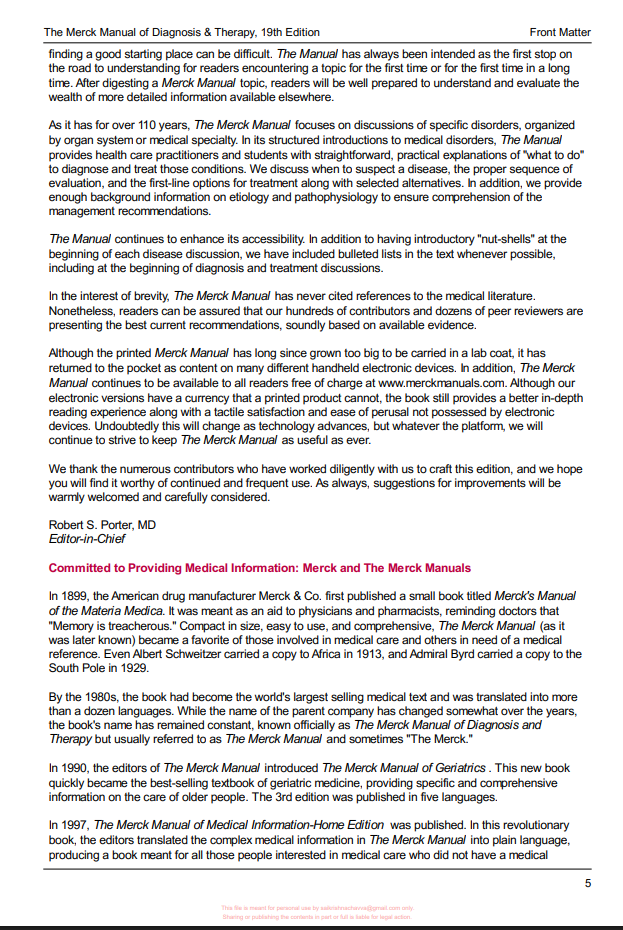

Above is the fifteenth page of the document.  
- It contains text with different fonts.  

Let's see how the text is extracted.

In [9]:
merk[14].page_content

'finding a good starting place can be difficult. The Manual has always been intended as the first stop on\nthe road to understanding for readers encountering a topic for the first time or for the first time in a long\ntime. After digesting a Merck Manual topic, readers will be well prepared to understand and evaluate the\nwealth of more detailed information available elsewhere.\nAs it has for over 110 years, The Merck Manual focuses on discussions of specific disorders, organized\nby organ system or medical specialty. In its structured introductions to medical disorders, The Manual\nprovides health care practitioners and students with straightforward, practical explanations of "what to do"\nto diagnose and treat those conditions. We discuss when to suspect a disease, the proper sequence of\nevaluation, and the first-line options for treatment along with selected alternatives. In addition, we provide\nenough background information on etiology and pathophysiology to ensure comprehension 

#### Checking the number of pages

In [10]:
#pages length
len(merk)

4114

## Data Chunking

In [11]:
text_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    encoding_name='cl100k_base',
    chunk_size=512,
    chunk_overlap= 20
)

In [12]:
document_chunks = pdf_loader.load_and_split(text_splitter)

In [13]:
len(document_chunks)

8523

In [14]:
document_chunks[-1].page_content

"Z\nZafirlukast 1879\nZalcitabine 1451\nin children 2854\nZaleplon 1709\nZanamivir 1407\nin influenza 1407, 1929\nZAP-70 (zeta-associated protein 70) deficiency 1092, 1108\nZavanelli maneuver 2680\nZellweger syndrome 2383, 3023\nZenker's diverticulum 125\nZidovudine 1451, 1453\nin children 2854\nZileuton 1881\nin asthma 1880\nZinc 49, 55, 3431-3432\nin common cold 1405\ndeficiency of 11, 49, 55\nin dermatophytoses 705\npoisoning with 3328, 3353\nrecommended dietary allowances for 50\nreference values for 3499\ntoxicity of 49, 55\ncopper deficiency and 49\nin Wilson's disease 52\nZinc oxide 2233\ngelatin formulation of 646, 672\nZinc pyrithione 647\nZinc shakes 55\nZipper injury 3239, 3240\nZiprasidone\nin agitation 1492\nin bipolar disorder 3059\npoisoning with 3347\nin schizophrenia 1566\nZoledronate 359, 361, 848\nZollinger-Ellison syndrome 95, 199, 200-201, 910\nmastocytosis vs 1125\nMenetrier's disease vs 132\npeptic ulcer disease vs 134\nZolmitriptan 1721\nZolpidem 1709, 3103\nZon

In [15]:
document_chunks[-2].page_content

'Y\nYaws 1266-1267\nforest 1379\nY chromosome 3373 (see also Genetic)\nabnormalities of 3005\nYeast infection (see also Fungal infection)\nvaginal 2542, 2544, 2545\nYellow fever 1400, 1429, 1437\nhepatic inflammation in 248\nvaccine against 1172, 1437, 3441\nYellow nail syndrome 732, 1995\npleural effusion in 1997\nYellow skin (see Jaundice)\nYersinia infection 1167, 1256-1257\nY. enterocolitica infection 147\nY. pestis infection 1924\nYew poisoning 3338\nYips 1762\nYo, antibodies to 1056\nYolk sac tumor 2476\nThe Merck Manual of Diagnosis & Therapy, 19th Edition\nY\n4103\nsaikrishnachavva@gmail.com\nJ4V7QIY9LH\nThis file is meant for personal use by saikrishnachavva@gmail.com only.\nSharing or publishing the contents in part or full is liable for legal action.'

In [16]:
document_chunks[502].page_content

'excoriation caused by scratching and secondary infection. A scraping of local skin is taken to rule out a\nfungal infection, and a stool sample should be examined for ova and parasites. Visible lesions should be\nbiopsied.\nFoods suspected of causing pruritus ani should be eliminated from the diet. Clothing should be loose, and\nbed clothing light. After bowel movements, the patient should cleanse the anal area with absorbent cotton\nor plain soft tissue moistened with water. Liberal, frequent dusting with nonmedicated talcum powder or\ncornstarch helps combat moisture. Hydrocortisone acetate 1% ointment, applied sparingly qid, may\nrelieve symptoms. Systemic causes and parasitic or fungal infections must be treated specifically.\nRectal Prolapse and Procidentia\nRectal prolapse is painless protrusion of the rectum through the anus. Procidentia is complete\nprolapse of the entire thickness of the rectum. Diagnosis is by inspection. Surgery is usually\nrequired in adults.\nTransient, m

In [17]:
document_chunks[503].page_content

"• For infants and children: Sometimes strapping buttocks together\n• For adults: Sometimes surgery\nIn infants and children, conservative treatment is most satisfactory. Causes of straining should be\neliminated. Firmly strapping the buttocks together with tape between bowel movements usually facilitates\nspontaneous resolution of the prolapse. For simple mucosal prolapse in adults, the excess mucosa can\nbe excised. For procidentia, an abdominal operation may be required. In patients who are very old or in\npoor health, a wire or synthetic plastic loop can encircle the sphincteric ring (Thiersch's procedure). Other\nperineal operations (eg, Delorme or Altemeier procedure) can be considered.\nThe Merck Manual of Diagnosis & Therapy, 19th Edition\nChapter 21. Anorectal Disorders\n253\nsaikrishnachavva@gmail.com\nJ4V7QIY9LH\nThis file is meant for personal use by saikrishnachavva@gmail.com only.\nSharing or publishing the contents in part or full is liable for legal action."

As expected, there are some overlaps:  

- The sentence '*• For infants and children: Sometimes strapping buttocks together\n• For adults: Sometimes surgery*' appears in both chunks.  
- If we increase the `chunk_overlap`, the overlapping length of the sentence will also increase.

## Embedding

In [18]:
embedding_model = SentenceTransformerEmbeddings(model_name='thenlper/gte-large')

/tmp/ipykernel_3177/4198310515.py:1: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the :class:`~langchain-huggingface package and should be used instead. To use it run `pip install -U :class:`~langchain-huggingface` and import as `from :class:`~langchain_huggingface import HuggingFaceEmbeddings``.
  embedding_model = SentenceTransformerEmbeddings(model_name='thenlper/gte-large')
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datase

modules.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/619 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/342 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

In [19]:
embedding_1 = embedding_model.embed_query(document_chunks[0].page_content)
embedding_2 = embedding_model.embed_query(document_chunks[1].page_content)

In [20]:
print("Dimension of the embedding vector ",len(embedding_1))
len(embedding_1)==len(embedding_2)

Dimension of the embedding vector  1024


True

* The embedding model provides a fixed-length vector for any number of chunks.  
* This is necessary because we want to compare them for similarity.

## Vector Database

In [21]:
out_dir = 'merk_db'

if not os.path.exists(out_dir):
  os.makedirs(out_dir)

In [22]:
vectorstore = Chroma.from_documents(
    document_chunks,
    embedding_model,
    persist_directory=out_dir
)

In [23]:
vectorstore = Chroma(persist_directory=out_dir,embedding_function=embedding_model)

/tmp/ipykernel_3177/2756559696.py:1: LangChainDeprecationWarning: The class `Chroma` was deprecated in LangChain 0.2.9 and will be removed in 1.0. An updated version of the class exists in the :class:`~langchain-chroma package and should be used instead. To use it run `pip install -U :class:`~langchain-chroma` and import as `from :class:`~langchain_chroma import Chroma``.
  vectorstore = Chroma(persist_directory=out_dir,embedding_function=embedding_model)


In [24]:
vectorstore.embeddings

HuggingFaceEmbeddings(client=SentenceTransformer(
  (0): Transformer({'max_seq_length': 512, 'do_lower_case': False, 'architecture': 'BertModel'})
  (1): Pooling({'word_embedding_dimension': 1024, 'pooling_mode_cls_token': False, 'pooling_mode_mean_tokens': True, 'pooling_mode_max_tokens': False, 'pooling_mode_mean_sqrt_len_tokens': False, 'pooling_mode_weightedmean_tokens': False, 'pooling_mode_lasttoken': False, 'include_prompt': True})
  (2): Normalize()
), model_name='thenlper/gte-large', cache_folder=None, model_kwargs={}, encode_kwargs={}, multi_process=False, show_progress=False)

In [25]:
vectorstore.similarity_search("Merck & Co.",k=5)

[Document(metadata={'source': '/content/drive/MyDrive/medical_diagnosis_manual.pdf', 'file_path': '/content/drive/MyDrive/medical_diagnosis_manual.pdf', 'moddate': '2026-03-15T06:22:15+00:00', 'modDate': 'D:20260315062215Z', 'producer': 'pdf-lib (https://github.com/Hopding/pdf-lib)', 'subject': '', 'author': '', 'creationdate': '2012-06-15T05:44:40+00:00', 'creationDate': 'D:20120615054440Z', 'total_pages': 4114, 'format': 'PDF 1.7', 'keywords': '', 'page': 15, 'creator': 'Atop CHM to PDF Converter', 'title': 'The Merck Manual of Diagnosis & Therapy, 19th Edition', 'trapped': ''}, page_content="degree. The book received critical acclaim and sold over 2 million copies. The Second Home Edition was\nreleased in 2003. Merck's commitment to providing comprehensive, understandable medical information\nto all people continued with The Merck Manual Home Health Handbook, published in 2009.\nThe Merck Manual of Health & Aging , published in 2004, continued Merck's commitment to education\nand ge

* From the retrieved chunks, we observe that all the chunks are related to the key terms [ 'Merck & Co.' ].

## Retriever

In [26]:
retriever = vectorstore.as_retriever(
    search_type='similarity',
    search_kwargs={'k': 2}
)

In [27]:
rel_docs = retriever.invoke("protocol for managing sepsis")
rel_docs

[Document(metadata={'title': 'The Merck Manual of Diagnosis & Therapy, 19th Edition', 'author': '', 'source': '/content/drive/MyDrive/medical_diagnosis_manual.pdf', 'subject': '', 'creator': 'Atop CHM to PDF Converter', 'moddate': '2026-03-15T06:22:15+00:00', 'trapped': '', 'keywords': '', 'modDate': 'D:20260315062215Z', 'total_pages': 4114, 'page': 2456, 'producer': 'pdf-lib (https://github.com/Hopding/pdf-lib)', 'file_path': '/content/drive/MyDrive/medical_diagnosis_manual.pdf', 'format': 'PDF 1.7', 'creationdate': '2012-06-15T05:44:40+00:00', 'creationDate': 'D:20120615054440Z'}, page_content="Parenteral antibiotics should be given after specimens of blood, body fluids, and wound sites have been\ntaken for Gram stain and culture. Very prompt empiric therapy, started immediately after suspecting\nsepsis, is essential and may be lifesaving. Antibiotic selection requires an educated guess based on the\nsuspected source, clinical setting, knowledge or suspicion of causative organisms an

- We can observe that the two relevant chunks contain the answer to the query.  
- If we increase the **`k`** value, there is a chance that we might find the answer in even more chunks.  
- This is a hyperparameter that we need to tune to get the best context.

# Defining the Response Generator

## Downloading and Loading the model

In [28]:
model_name_or_path = "TheBloke/Mistral-7B-Instruct-v0.2-GGUF"
model_basename = "mistral-7b-instruct-v0.2.Q6_K.gguf"

In [29]:
model_path = hf_hub_download(
    repo_id=model_name_or_path,
    filename=model_basename
)

mistral-7b-instruct-v0.2.Q6_K.gguf:   0%|          | 0.00/5.94G [00:00<?, ?B/s]

In [30]:
# if the runtime is connected to GPU.
llm = Llama(
    model_path=model_path,
    n_ctx=5000,
    n_gpu_layers=38,
    n_batch=512
)

AVX = 1 | AVX2 = 1 | AVX512 = 0 | AVX512_VBMI = 0 | AVX512_VNNI = 0 | FMA = 1 | NEON = 0 | ARM_FMA = 0 | F16C = 1 | FP16_VA = 0 | WASM_SIMD = 0 | BLAS = 1 | SSE3 = 1 | SSSE3 = 1 | VSX = 0 | 


In [31]:
llm("What is the protocol for managing sepsis in a critical care unit?")['choices'][0]['text']

'\n\nSepsis is a life-threatening condition that can arise from an infection, and it requires prompt recognition and aggressive management in a critical care unit. The following steps outline the general approach to managing sepsis in a critical care setting:\n\n1. Early recognition: Suspect sepsis in any patient with suspected or confirmed infection who is exhibiting signs of organ dysfunction, such as altered mental status, decreased urine output, respiratory distress, or hypotension. Use the Sequential Organ Failure Assessment (SOFA) score to assess organ dysfunction and monitor for progression'

- The response seems generic and appears to be derived from another article. Let's provide our own context and align the response with our needs.

## System and User Prompt Template

Prompts guide the model to generate accurate responses. Here, we define two parts:

    1. The system message describing the assistant's role.
    2. A user message template including context and the question.

In [32]:
qna_system_message = """
You are an assistant whose work is to review the report and provide the appropriate answers from the context.
User input will have the context required by you to answer user questions.
This context will begin with the token: ###Context.
The context contains references to specific portions of a document relevant to the user query.

User questions will begin with the token: ###Question.

Please answer only using the context provided in the input. Do not mention anything about the context in your final answer.

If the answer is not found in the context, respond "I don't know".
"""

In [33]:
qna_user_message_template = """
###Context
Here are some documents that are relevant to the question mentioned below.
{context}

###Question
{question}
"""

## Response Function

In [3]:
def generate_rag_response(user_input,k=3,max_tokens=128,temperature=0,top_p=0.95,top_k=50):
    global qna_system_message,qna_user_message_template
    # Retrieve relevant document chunks
    retriever.search_kwargs["k"] = k
    relevant_document_chunks = retriever.invoke(user_input)
    context_list = [d.page_content for d in relevant_document_chunks]

    # Combine document chunks into a single context
    context_for_query = ". ".join(context_list)

    user_message = qna_user_message_template.replace('{context}', context_for_query)
    user_message = user_message.replace('{question}', user_input)

    prompt = qna_system_message + '\n' + user_message

    # Generate the response
    try:
        response = llm(
                  prompt=prompt,
                  max_tokens=max_tokens,
                  temperature=temperature,
                  top_p=top_p,
                  top_k=top_k
                  )

        # Extract and print the model's response
        response = response['choices'][0]['text'].strip()
    except Exception as e:
        response = f'Sorry, I encountered the following error: \n {e}'

    return response

# Question Answering using RAG

### Query 1: What is the protocol for managing sepsis in a critical care unit?

In [35]:
user_input = "What is the protocol for managing sepsis in a critical care unit?"
print(generate_rag_response(user_input))

Llama.generate: prefix-match hit


Based on the context, the protocol for managing sepsis in a critical care unit includes:
1. Prompt empiric antibiotic therapy, started immediately after suspecting sepsis.
2. Selection of antibiotics based on suspected source, clinical setting, knowledge or suspicion of causative organisms and sensitivity patterns common to that specific inpatient unit, and previous culture results.
3. Continuation of antibiotics for at least 5 days after shock resolves and evidence of infection subsides.
4. Drainage of abscesses and surgical excision of necrot


- The answer is clear, concise, and focused, without any unnecessary information.

### Query 2: What are the common symptoms of appendicitis, and can it be cured via medicine? If not, what surgical procedure should be followed to treat it?

In [36]:
user_input_2 = "What are the common symptoms of appendicitis, and can it be cured via medicine? If not, what surgical procedure should be followed to treat it?"
generate_rag_response(user_input_2)

Llama.generate: prefix-match hit


'Based on the context provided, the answer would be: Appendicitis is characterized by abdominal pain, anorexia, and abdominal tenderness. It cannot be cured via medicine alone; instead, surgical removal of the appendix (appendectomy) is required for treatment.'

- The answer is clear and precise for both the questions without any wrong information

### Query 3: What are the effective treatments or solutions for addressing sudden patchy hair loss, commonly seen as localized bald spots on the scalp, and what could be the possible causes behind it?

In [37]:
user_input_3 = "What are the effective treatments or solutions for addressing sudden patchy hair loss, commonly seen as localized bald spots on the scalp, and what could be the possible causes behind it?"
generate_rag_response(user_input_3)

Llama.generate: prefix-match hit


'Based on the context provided, the condition being described is Alopecia Areata. The effective treatments for this condition include topical, intralesional, or systemic corticosteroids, topical minoxidil, topical anthralin, topical immunotherapy (diphencyprone or squaric acid dibutylester), or psoralen plus ultraviolet A (PUVA). The possible causes behind this condition are thought to be an autoimmune disorder affecting genetically susceptible people exposed to unclear environmental triggers.'

- The treatment approach and potential causes are clearly explained.  
- The condition *Alopecia Areata* is also identified in the response.

###Query 4: What treatments are recommended for a person who has sustained a physical injury to brain tissue, resulting in temporary or permanent impairment of brain function?

In [38]:
user_input_4="What treatments are recommended for a person who has sustained a physical injury to brain tissue, resulting in temporary or permanent impairment of brain function?"
generate_rag_response(user_input_4)

Llama.generate: prefix-match hit


'I. Supportive care including preventing systemic complications, providing good nutrition, and preventing pressure ulcers.\nII. Surgery to place monitors to track intracranial pressure, decompress the brain if intracranial pressure is increased, or remove intracranial hematomas.\nIII. Rehabilitation services for cognitive and emotional areas.\nAnswer: I, II.'

- Treatments are not shown in the answer . Need to improve the prompt and fine tuning is required.

###Query 5: What are the necessary precautions and treatment steps for a person who has fractured their leg during a hiking trip, and what should be considered for their care and recovery?

In [39]:
user_input_5 = "What are the necessary precautions and treatment steps for a person who has fractured their leg during a hiking trip, and what should be considered for their care and recovery?"
generate_rag_response(user_input_5)

Llama.generate: prefix-match hit


"Based on the context provided, here's the answer:\n\nThe person with a fractured leg should follow these steps:\n1. Elevate the injured limb above heart level for the first 2 days to minimize swelling.\n2. Apply warmth (using a heating pad) for 15 to 20 minutes after the first 48 hours to relieve pain and speed healing.\n3. Immobilize the joints proximal and distal to the injury using either a cast or a splint, depending on the severity and duration of immobilization required."

- Necessary precautions, treatment, and care are clearly outlined.  
- As expected, the model performs well and avoids hallucinations.

## Fine-tuning Parameters

### Query 1: Who are the authors of this article and who published this article ?

In [40]:
user_input = "What is the protocol for managing sepsis in a critical care unit?"
generate_rag_response(user_input, max_tokens=100)

Llama.generate: prefix-match hit


'Based on the context, the protocol for managing sepsis in a critical care unit includes:\n1. Prompt empiric antibiotic therapy, started immediately after suspecting sepsis.\n2. Selection of antibiotics based on suspected source, clinical setting, knowledge or suspicion of causative organisms and sensitivity patterns common to that specific inpatient unit, and previous culture results.\n3. Continuation of antibiotics for at least 5 days after shock res'

- Even if the **`max_tokens`** is set to 100, the model still didn't generate that many, as the query could be answered with a limited number of tokens.  

- One of the reasons could be that the temperature is set to 0, making the model more deterministic and less creative.

### Query 2: What are the common symptoms of appendicitis, and can it be cured via medicine? If not, what surgical procedure should be followed to treat it?.

In [41]:
user_input_2 = "What are the common symptoms of appendicitis, and can it be cured via medicine? If not, what surgical procedure should be followed to treat it?"
generate_rag_response(user_input_2, temperature=0.1, max_tokens=350)

Llama.generate: prefix-match hit


'Based on the context provided, the answer would be: The common symptoms of appendicitis include abdominal pain, anorexia, and abdominal tenderness. Appendicitis cannot be cured via medicine alone; surgery (appendectomy) is required for treatment.'

- Result is almost similar to the previous answer "Based on the context provided, the answer would be: Appendicitis is characterized by abdominal pain, anorexia, and abdominal tenderness. It cannot be cured via medicine alone; instead, surgical removal of the appendix (appendectomy) is required for treatment."

### Query 3: What are the effective treatments or solutions for addressing sudden patchy hair loss, commonly seen as localized bald spots on the scalp, and what could be the possible causes behind it?

In [42]:
user_input_3 = "What are the effective treatments or solutions for addressing sudden patchy hair loss, commonly seen as localized bald spots on the scalp, and what could be the possible causes behind it?"
generate_rag_response(user_input_3, top_p=0.98, top_k=20, max_tokens=256)

Llama.generate: prefix-match hit


'Based on the context provided, the condition being described is Alopecia Areata. The effective treatments for this condition include topical, intralesional, or systemic corticosteroids, topical minoxidil, topical anthralin, topical immunotherapy (diphencyprone or squaric acid dibutylester), or psoralen plus ultraviolet A (PUVA). The possible causes behind this condition are thought to be an autoimmune disorder affecting genetically susceptible people exposed to unclear environmental triggers.'

- The result remains largely consistent with the previous answer despite changes in parameters.

###Query 4: What treatments are recommended for a person who has sustained a physical injury to brain tissue, resulting in temporary or permanent impairment of brain function?

In [ ]:
user_input_4 = "What treatments are recommended for a person who has sustained a physical injury to brain tissue, resulting in temporary or permanent impairment of brain function?"
generate_rag_response(user_input_4, top_k=10, max_tokens=256)

###Query 5 : What are the necessary precautions and treatment steps for a person who has fractured their leg during a hiking trip, and what should be considered for their care and recovery?

In [44]:
user_input_5="What are the necessary precautions and treatment steps for a person who has fractured their leg during a hiking trip, and what should be considered for their care and recovery?"
generate_rag_response(user_input_5,top_k=20, max_tokens=256)

Llama.generate: prefix-match hit


"Based on the context provided, here's the answer:\n\nThe person with a fractured leg should follow these steps:\n1. Elevate the injured limb above heart level for the first 2 days to minimize swelling.\n2. Apply warmth (using a heating pad) for 15 to 20 minutes after the first 48 hours to relieve pain and speed healing.\n3. Immobilize the joints proximal and distal to the injury using either a cast or a splint, depending on the severity and duration of immobilization required.\n   - If a cast is used, keep it dry, never put any object inside it, inspect its edges and skin around it daily, apply lotion to any red or sore areas, pad any rough edges with soft material, and seek medical care if an odor emanates from within the cast or a fever develops.\n   - If a splint is used, apply ice, move more, and do not contribute to compartment syndrome.\n4. For fractures that require prolonged immobilization (more than 3 to 4 weeks), be aware of potential complications such as stiffness, contrac

- Increasing **`max_tokens`** allows the answer to include more detailed, accurate information about the fractured leg, including recovery timelines, without introducing hallucinations.

# Output Evaluation

Let us now use the LLM-as-a-judge method to check the quality of the RAG system on two parameters - retrieval and generation. We illustrate this evaluation based on the answeres generated to the question from the previous section.

- We are using the same Mistral model for evaluation, so basically here the llm is rating itself on how well he has performed in the task.

### Defining the Evaluation Prompts

In [45]:
groundedness_rater_system_message = """
You are tasked with rating AI generated answers to questions posed by users.
You will be presented a question, context used by the AI system to generate the answer and an AI generated answer to the question.
In the input, the question will begin with ###Question, the context will begin with ###Context while the AI generated answer will begin with ###Answer.

Evaluation criteria:
The task is to judge the extent to which the metric is followed by the answer.
1 - The metric is not followed at all
2 - The metric is followed only to a limited extent
3 - The metric is followed to a good extent
4 - The metric is followed mostly
5 - The metric is followed completely

Metric:
The answer should be derived only from the information presented in the context

Instructions:
1. First write down the steps that are needed to evaluate the answer as per the metric.
2. Give a step-by-step explanation if the answer adheres to the metric considering the question and context as the input.
3. Next, evaluate the extent to which the metric is followed.
4. Use the previous information to rate the answer using the evaluaton criteria and assign a score.
"""

In [46]:
relevance_rater_system_message = """
You are tasked with rating AI generated answers to questions posed by users.
You will be presented a question, context used by the AI system to generate the answer and an AI generated answer to the question.
In the input, the question will begin with ###Question, the context will begin with ###Context while the AI generated answer will begin with ###Answer.

Evaluation criteria:
The task is to judge the extent to which the metric is followed by the answer.
1 - The metric is not followed at all
2 - The metric is followed only to a limited extent
3 - The metric is followed to a good extent
4 - The metric is followed mostly
5 - The metric is followed completely

Metric:
Relevance measures how well the answer addresses the main aspects of the question, based on the context.
Consider whether all and only the important aspects are contained in the answer when evaluating relevance.

Instructions:
1. First write down the steps that are needed to evaluate the context as per the metric.
2. Give a step-by-step explanation if the context adheres to the metric considering the question as the input.
3. Next, evaluate the extent to which the metric is followed.
4. Use the previous information to rate the context using the evaluaton criteria and assign a score.
"""

In [47]:
user_message_template = """
###Question
{question}

###Context
{context}

###Answer
{answer}
"""

### Defining the Evaluation Function

In [48]:
def generate_ground_relevance_response(user_input,k=3,max_tokens=1024,temperature=0,top_p=0.95,top_k=50):
    global qna_system_message,qna_user_message_template
    # Retrieve relevant document chunks
    relevant_document_chunks = retriever.get_relevant_documents(query=user_input,k=3)
    context_list = [d.page_content for d in relevant_document_chunks]
    context_for_query = ". ".join(context_list)

    # Combine user_prompt and system_message to create the prompt
    prompt = f"""[INST]{qna_system_message}\n
                {'user'}: {qna_user_message_template.format(context=context_for_query, question=user_input)}
                [/INST]"""

    response = llm(
            prompt=prompt,
            max_tokens=max_tokens,
            temperature=temperature,
            top_p=top_p,
            top_k=top_k,
            stop=['INST'],
            )

    answer =  response["choices"][0]["text"]
    # Combine user_prompt and system_message to create the prompt
    groundedness_prompt = f"""[INST]{groundedness_rater_system_message}\n
                {'user'}: {user_message_template.format(context=context_for_query, question=user_input, answer=answer)}
                [/INST]"""

    # Combine user_prompt and system_message to create the prompt
    relevance_prompt = f"""[INST]{relevance_rater_system_message}\n
                {'user'}: {user_message_template.format(context=context_for_query, question=user_input, answer=answer)}
                [/INST]"""

    response_1 = llm(
            prompt=groundedness_prompt,
            max_tokens=max_tokens,
            temperature=temperature,
            top_p=top_p,
            top_k=top_k,
            stop=['INST'],
            )

    response_2 = llm(
            prompt=relevance_prompt,
            max_tokens=max_tokens,
            temperature=temperature,
            top_p=top_p,
            top_k=top_k,
            stop=['INST'],
            )

    return response_1['choices'][0]['text'],response_2['choices'][0]['text']

### Query 1: What is the protocol for managing sepsis in a critical care unit?

In [49]:
user_input = "What is the protocol for managing sepsis in a critical care unit?"
ground,rel = generate_ground_relevance_response(user_input,max_tokens=350)

print(ground,end="\n\n")
print(rel)

/tmp/ipykernel_3177/4091705068.py:4: LangChainDeprecationWarning: The method `BaseRetriever.get_relevant_documents` was deprecated in langchain-core 0.1.46 and will be removed in 1.0. Use :meth:`~invoke` instead.
  relevant_document_chunks = retriever.get_relevant_documents(query=user_input,k=3)
Llama.generate: prefix-match hit
Llama.generate: prefix-match hit
Llama.generate: prefix-match hit


 Steps to evaluate the answer:
1. Identify the key information related to managing sepsis in a critical care unit from the context.
2. Compare the AI generated answer with the identified key information.
3. Determine if the answer is derived only from the information presented in the context.

Explanation:
The AI generated answer includes administering antibiotics promptly based on suspected source, clinical setting, and previous culture results, which is consistent with the context. The answer also mentions one regimen for septic shock of unknown cause, which includes gentamicin or tobramycin 5.1 mg/kg IV once/day plus a 3rd-generation cephalosporin (cefotaxime 2 g q 6 to 8 h or ceftriaxone 2 g once/day), or ceftazidime 2 g IV q 8 h if Pseudomonas is suspected, and Vancomycin must be added if resistant staphylococci or enterococci are suspected. These details are also present in the context. The answer also mentions normalization of blood glucose, corticosteroid therapy, activated pro

### Query 2: What are the common symptoms of appendicitis, and can it be cured via medicine? If not, what surgical procedure should be followed to treat it?

In [50]:
user_input_2 = "What are the common symptoms of appendicitis, and can it be cured via medicine? If not, what surgical procedure should be followed to treat it?"
ground,rel = generate_ground_relevance_response(user_input_2,max_tokens=1024)

print(ground,end="\n\n")
print(rel)

Llama.generate: prefix-match hit
Llama.generate: prefix-match hit
Llama.generate: prefix-match hit


 Steps to evaluate the answer:
1. Identify the information in the context related to the question.
2. Determine if the symptoms mentioned in the question are present in the context.
3. Check if the treatment options given in the answer are consistent with the context.
4. Verify that the answer is derived solely from the context and not any external sources.

Explanation:
The question asks about the common symptoms of appendicitis and whether it can be cured via medicine. The context provides information on the diagnosis, treatment, and prognosis of appendicitis. The symptoms mentioned in the question are present in the context as abdominal pain, anorexia, and abdominal tenderness. The context also states that surgery is the standard treatment for appendicitis and that antibiotics alone cannot cure it. Therefore, the answer "The common symptoms of appendicitis include abdominal pain, anorexia, and abdominal tenderness. Appendicitis cannot be cured via medicine alone; the standard treatm

### Query 3: What are the effective treatments or solutions for addressing sudden patchy hair loss, commonly seen as localized bald spots on the scalp, and what could be the possible causes behind it?

In [51]:
user_input_3 = "What are the effective treatments or solutions for addressing sudden patchy hair loss, commonly seen as localized bald spots on the scalp, and what could be the possible causes behind it?"
ground,rel = generate_ground_relevance_response(user_input_3,max_tokens=500)

print(ground,end="\n\n")
print(rel)

Llama.generate: prefix-match hit
Llama.generate: prefix-match hit
Llama.generate: prefix-match hit


 Steps to evaluate the answer:
1. Identify the information in the context related to effective treatments or solutions for sudden patchy hair loss.
2. Check if the AI generated answer includes only the information from the context and not any additional or incorrect information.
3. Verify that the possible causes mentioned in the answer are also present in the context.

Explanation:
The AI generated answer adheres to the metric as it is derived solely from the information presented in the context. The answer includes all the effective treatments and solutions for sudden patchy hair loss mentioned in the context, and also mentions the possible causes of this condition that are discussed in the context.

Evaluation:
The metric is followed completely.

Rating:
Based on the evaluation criteria, I would rate the answer as a 5 because it follows the metric completely.

 Steps to evaluate the context as per the relevance metric:
1. Identify the main aspects of the question: effective treatmen

###Query 4 :What treatments are recommended for a person who has sustained a physical injury to brain tissue, resulting in temporary or permanent impairment of brain function?

In [52]:
user_input_4 = "What treatments are recommended for a person who has sustained a physical injury to brain tissue, resulting in temporary or permanent impairment of brain function?"
ground,rel = generate_ground_relevance_response(user_input_4,max_tokens=500)

print(ground,end="\n\n")
print(rel)

Llama.generate: prefix-match hit
Llama.generate: prefix-match hit
Llama.generate: prefix-match hit


 Steps to evaluate the answer:
1. Identify the key information in the context related to treatments for traumatic brain injuries (TBI).
2. Determine if the AI generated answer is derived only from the information presented in the context.
3. Evaluate the extent to which the metric is followed.

Explanation:
The AI generated answer mentions that there is no specific treatment for TBI, but supportive care is important. It also lists some aspects of supportive care such as preventing systemic complications due to immobilization, providing good nutrition, and preventing pressure ulcers. The context provides information about the initial treatment for TBI which includes maintaining adequate brain perfusion and oxygenation, preventing complications, and subsequent rehabilitation. The AI generated answer is derived directly from this information in the context.

Evaluation:
The metric is followed completely as the answer is derived only from the information presented in the context.

Rating:


###Query 5: What are the necessary precautions and treatment steps for a person who has fractured their leg during a hiking trip, and what should be considered for their care and recovery?

In [53]:
user_input_5 = "What are the necessary precautions and treatment steps for a person who has fractured their leg during a hiking trip, and what should be considered for their care and recovery?"
ground,rel = generate_ground_relevance_response(user_input_5,max_tokens=500)

print(ground,end="\n\n")
print(rel)

Llama.generate: prefix-match hit
Llama.generate: prefix-match hit
Llama.generate: prefix-match hit


 Steps to evaluate the answer:
1. Identify the information in the context related to precautions and treatment steps for a person with a fractured leg.
2. Check if the AI generated answer includes only the information from the context.
3. If yes, rate the answer as following the metric completely.
4. If not, evaluate the extent to which the answer follows the metric based on the amount of additional information provided.

Explanation:
The AI generated answer includes all the necessary precautions and treatment steps for a person with a fractured leg as presented in the context. Therefore, the answer adheres to the metric completely.

Rating:
Based on the evaluation criteria, I would rate the answer as 5 - The metric is followed completely.

 Steps to evaluate the context as per the relevance metric:
1. Identify the main aspects of the question: necessary precautions and treatment steps for a person with a fractured leg.
2. Read through the context to understand if it addresses these ma

# Business Insights and Recommendations

- The time required to build a vector database grows with the number of pages in the PDF.  
- The retrieval parameter **`k`** is crucial, as relevant information may be distributed across multiple contexts.  
- **`chunk_overlap`** helps maintain coherence, particularly when information spans across adjacent chunks.  
- **`max_tokens`** should align with query complexity. Higher values enable more detailed responses, while simpler queries remain concise due to prompt design and a zero **`temperature`** setting.  
- Fine-tuning prompt design and temperature allows better control over response length and creativity.  
- RAG parameters should be continuously optimized based on the specific use case to achieve the best results.  
- Emphasize groundedness and relevance during evaluation to ensure accurate and context-aware outputs.  
- Implement a feedback loop to iteratively refine parameters and enhance performance across diverse query types.